In [1]:
# Fitrya Irfan_202431073
# Langkah 1 - Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [2]:
# Fitrya Irfan_202431073
# Langkah 2 - Membaca dataset
# Dataset : California Housing Prices (Kaggle, camnugent/california-housing-prices)
# Link    : https://www.kaggle.com/datasets/camnugent/california-housing-prices
df = pd.read_csv('housing.csv')
print('Jumlah baris x kolom :', df.shape)
df.head()

Jumlah baris x kolom : (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
# Fitrya Irfan_202431073
# Langkah 2 (lanjutan) - info() dan describe()
df.info()
print()
df.describe().round(2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB



,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.00,20640.00,20640.00,20640.00,20433.00,20640.00,20640.00,20640.00,20640.00
mean,-119.57,35.63,28.64,2635.76,537.87,1425.48,499.54,3.87,206855.82
std,2.00,2.14,12.59,2181.62,421.39,1132.46,382.33,1.90,115395.62
min,-124.35,32.54,1.00,2.00,1.00,3.00,1.00,0.50,14999.00
25%,-121.80,33.93,18.00,1447.75,296.00,787.00,280.00,2.56,119600.00
50%,-118.49,34.26,29.00,2127.00,435.00,1166.00,409.00,3.53,179700.00
75%,-118.01,37.71,37.00,3148.00,647.00,1725.00,605.00,4.74,264725.00
max,-114.31,41.95,52.00,39320.00,6445.00,35682.00,6082.00,15.00,500001.00


In [4]:
# Fitrya Irfan_202431073
# Langkah 3 - Pembersihan data
print('isna().sum() SEBELUM pembersihan:')
print(df.isna().sum())

# longitude & latitude dibuang: tujuan klasterisasi adalah profil sosial-ekonomi
# distrik, bukan posisi geografis
# ocean_proximity berupa kategori (label), tidak dipakai sebagai fitur K-Means
df_bersih = df.drop(columns=['longitude', 'latitude']).copy()

# nilai kosong pada total_bedrooms diisi dengan median kolomnya
median_bedrooms = df_bersih['total_bedrooms'].median()
df_bersih['total_bedrooms'] = df_bersih['total_bedrooms'].fillna(median_bedrooms)

print()
print('isna().sum() SESUDAH pembersihan:')
print(df_bersih.isna().sum())

isna().sum() SEBELUM pembersihan:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

isna().sum() SESUDAH pembersihan:
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64


In [5]:
# Fitrya Irfan_202431073
# Langkah 4 - Memilih fitur klasterisasi
# Alasan: keempat fitur menggambarkan daya beli (median_income, median_house_value),
# usia hunian (housing_median_age) dan kepadatan (population) suatu distrik
fitur = ['median_income', 'median_house_value', 'housing_median_age', 'population']
X = df_bersih[fitur]

print('Korelasi antarfitur:')
X.corr().round(2)

Korelasi antarfitur:


,median_income,median_house_value,housing_median_age,population
median_income,1.00,0.69,-0.12,0.00
median_house_value,0.69,1.00,0.11,-0.02
housing_median_age,-0.12,0.11,1.00,-0.30
population,0.00,-0.02,-0.30,1.00


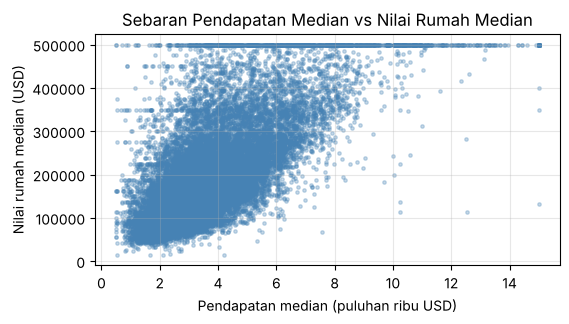

In [6]:
# Fitrya Irfan_202431073
# Langkah 5 - Scatter plot sebaran data
plt.figure(figsize=(6, 3))
plt.scatter(X['median_income'], X['median_house_value'],
            s=6, alpha=0.3, color='steelblue')
plt.title('Sebaran Pendapatan Median vs Nilai Rumah Median')
plt.xlabel('Pendapatan median (puluhan ribu USD)')
plt.ylabel('Nilai rumah median (USD)')
plt.grid(alpha=0.3)
plt.show()

In [7]:
# Fitrya Irfan_202431073
# Langkah 6 - Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=fitur)

print('Rata-rata setelah standarisasi:')
print(X_scaled_df.mean().round(4))
print()
print('Simpangan baku setelah standarisasi:')
print(X_scaled_df.std(ddof=0).round(4))

Rata-rata setelah standarisasi:
median_income         0.0
median_house_value   -0.0
housing_median_age    0.0
population           -0.0
dtype: float64

Simpangan baku setelah standarisasi:
median_income         1.0
median_house_value    1.0
housing_median_age    1.0
population            1.0
dtype: float64


In [8]:
# Fitrya Irfan_202431073
# Langkah 7 - Menghitung inertia untuk k = 1 sampai 10
inertia = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=0)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

tabel_inertia = pd.DataFrame({'k': range(1, 11), 'inertia': np.round(inertia, 2)})
print(tabel_inertia.to_string(index=False))

 k  inertia
 1 82560.00
 2 60216.42
 3 47260.16
 4 39102.62
 5 34314.59
 6 30544.93
 7 27706.06
 8 25393.67
 9 23818.98
10 22533.48


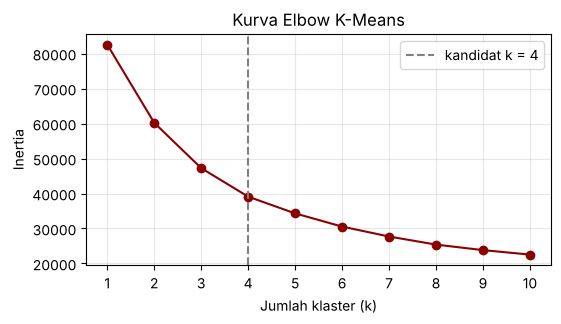

In [9]:
# Fitrya Irfan_202431073
# Langkah 8 - Kurva elbow
plt.figure(figsize=(6, 3))
plt.plot(range(1, 11), inertia, marker='o', color='darkred')
plt.axvline(4, linestyle='--', color='gray', label='kandidat k = 4')
plt.title('Kurva Elbow K-Means')
plt.xlabel('Jumlah klaster (k)')
plt.ylabel('Inertia')
plt.xticks(range(1, 11))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [10]:
# Fitrya Irfan_202431073
# Langkah 9 - Silhouette score dan Davies-Bouldin Index untuk k = 2 sampai 6
hasil = []
for k in range(2, 7):
    model = KMeans(n_clusters=k, n_init=10, random_state=0)
    label = model.fit_predict(X_scaled)
    hasil.append({'k': k,
                  'Silhouette': round(silhouette_score(X_scaled, label), 4),
                  'DBI': round(davies_bouldin_score(X_scaled, label), 4)})

tabel_eval = pd.DataFrame(hasil)
print(tabel_eval.to_string(index=False))
print()
print('Arah penilaian:')
print('- Silhouette makin TINGGI makin baik (maksimum 1)')
print('- DBI makin RENDAH makin baik (minimum 0)')

 k  Silhouette    DBI
 2      0.3183 1.3492
 3      0.2663 1.2752
 4      0.2677 1.1452
 5      0.2566 1.1753
 6      0.2516 1.1224

Arah penilaian:
- Silhouette makin TINGGI makin baik (maksimum 1)
- DBI makin RENDAH makin baik (minimum 0)


In [11]:
# Fitrya Irfan_202431073
# Langkah 10 - Model akhir dengan k = 4
k_final = 4
kmeans_final = KMeans(n_clusters=k_final, n_init=10, random_state=0)
label_final = kmeans_final.fit_predict(X_scaled)

print('cluster_centers_ (skala terstandarisasi):')
pusat = pd.DataFrame(kmeans_final.cluster_centers_, columns=fitur).round(3)
print(pusat)
print()
print('Jumlah anggota tiap klaster:')
print(pd.Series(label_final).value_counts().sort_index())

cluster_centers_ (skala terstandarisasi):
   median_income  median_house_value  housing_median_age  population
0         -0.440              -0.347               0.842      -0.276
1          1.340               1.538               0.089      -0.227
2          0.030              -0.103              -0.937       2.564
3         -0.265              -0.457              -0.817      -0.083

Jumlah anggota tiap klaster:
0    8078
1    4025
2    1449
3    7088
Name: count, dtype: int64


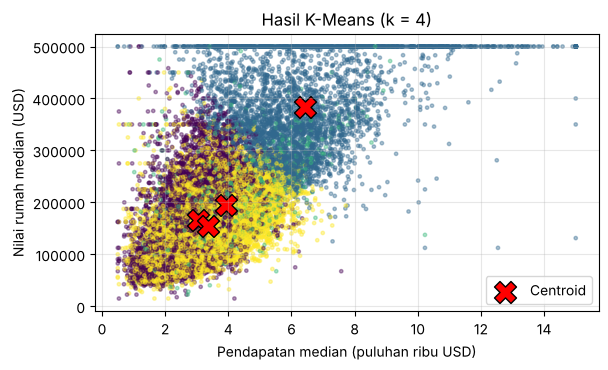

In [12]:
# Fitrya Irfan_202431073
# Langkah 11 - Visualisasi hasil klaster beserta centroid (dalam skala asli)
centroid_asli = scaler.inverse_transform(kmeans_final.cluster_centers_)

plt.figure(figsize=(6.5, 3.6))
plt.scatter(X['median_income'], X['median_house_value'],
            c=label_final, cmap='viridis', s=6, alpha=0.4)
plt.scatter(centroid_asli[:, 0], centroid_asli[:, 1], c='red', marker='X',
            s=250, edgecolors='black', label='Centroid')
plt.title('Hasil K-Means (k = 4)')
plt.xlabel('Pendapatan median (puluhan ribu USD)')
plt.ylabel('Nilai rumah median (USD)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [13]:
# Fitrya Irfan_202431073
# Langkah 12 - Profil klaster (rata-rata fitur ASLI per klaster)
df_klaster = df_bersih.copy()
df_klaster['klaster'] = label_final

profil = df_klaster.groupby('klaster')[fitur].mean().round(2)
profil['jumlah_distrik'] = df_klaster.groupby('klaster').size()
profil

,median_income,median_house_value,housing_median_age,population,jumlah_distrik
klaster,,,,,
0,3.04,166838.38,39.23,1113.51,8078
1,6.42,384320.24,29.75,1168.67,4025
2,3.93,195049.28,16.83,4333.65,1449
3,3.37,154101.06,18.35,1332.32,7088


In [14]:
# Fitrya Irfan_202431073
# Langkah 12 (lanjutan) - Pemberian nama klaster berdasarkan profil
nama_klaster = {
    0: 'Hunian Lama Menengah-Bawah',
    1: 'Distrik Makmur',
    2: 'Distrik Padat Penduduk',
    3: 'Hunian Baru Terjangkau',
}
df_klaster['nama_klaster'] = df_klaster['klaster'].map(nama_klaster)
print(df_klaster.groupby(['klaster', 'nama_klaster']).size())

klaster  nama_klaster              
0        Hunian Lama Menengah-Bawah    8078
1        Distrik Makmur                4025
2        Distrik Padat Penduduk        1449
3        Hunian Baru Terjangkau        7088
dtype: int64


In [15]:
# Fitrya Irfan_202431073
# Langkah 13 - Evaluasi akhir model
sil_final = silhouette_score(X_scaled, label_final)
dbi_final = davies_bouldin_score(X_scaled, label_final)
print('Model akhir K-Means (k = 4)')
print('Silhouette score      :', round(sil_final, 4))
print('Davies-Bouldin Index  :', round(dbi_final, 4))
print('Inertia               :', round(kmeans_final.inertia_, 2))

Model akhir K-Means (k = 4)
Silhouette score      : 0.2677
Davies-Bouldin Index  : 1.1452
Inertia               : 39102.62
